# Chapitre 10 - Lab : les algorithmes du traitement par lots dans PostgreSQL

Les algorithmes des cours 1 à 5 ne sont pas propres aux frameworks distribués : un moteur
de base de données les emploie aussi pour ses requêtes analytiques. Ce lab les observe
dans PostgreSQL 16, à travers ses plans d'exécution (`EXPLAIN ANALYZE`) :

1. le **tri externe** : quand la mémoire de tri (`work_mem`) ne suffit plus, PostgreSQL
   trie par segments sur disque puis fusionne (cours 1) ;
2. l'**agrégation** par hachage ou par tri, et le débordement sur disque ;
3. les **algorithmes de jointure** : hachage, fusion, boucles imbriquées, et la jointure
   par hachage **partitionnée** quand la table de hachage ne tient pas en mémoire
   (cours 3) ;
4. le **chargement en masse** : insertions une à une, par lots, ou `COPY` (cours 5) ;
5. **construire puis basculer** : publier une nouvelle version d'une table d'un coup,
   sans que les lecteurs voient jamais un état intermédiaire (cours 5).

**Démarrer et arrêter les services** (depuis la racine du dépôt) :

```bash
docker compose -f docker/batch/compose.yml -p ddia_batch up -d     # démarrer
docker compose -f docker/batch/compose.yml -p ddia_batch down -v   # arrêter et effacer
```

PostgreSQL écoute sur le port **11132** de la machine (utilisateur, mot de passe et base :
`ddia` / `ddia` / `lots`). Le parallélisme intra-requête est désactivé
(`max_parallel_workers_per_gather=0`) pour que les plans restent lisibles. Les durées
dépendent de la machine ; ce sont les ordres de grandeur et les plans qui comptent.

In [1]:
import re
import threading
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg

from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 110)

DSN = "host=localhost port=11132 user=ddia password=ddia dbname=lots"
con = None
for essai in range(30):
    try:
        con = psycopg.connect(DSN, autocommit=True)
        break
    except psycopg.OperationalError:
        time.sleep(1)
assert con is not None, "PostgreSQL ne répond pas : avez-vous lancé docker compose up ?"
print(con.execute("SELECT version()").fetchone()[0][:60])


def q(sql, params=None):
    return con.execute(sql, params).fetchall()


def plan(sql):
    """Plan réel (EXPLAIN ANALYZE) sous forme de texte, sans les durées par nœud."""
    return "\n".join(r[0] for r in q("EXPLAIN (ANALYZE, COSTS OFF, TIMING OFF, SUMMARY OFF) " + sql))


def duree_serveur(sql, repet=3):
    """Durée médiane d'exécution côté serveur (s), lue dans EXPLAIN ANALYZE : on exclut
    ainsi le transfert des lignes vers le client, qui masquerait le coût des algorithmes."""
    ts = []
    for _ in range(repet):
        p = "\n".join(r[0] for r in q("EXPLAIN (ANALYZE, TIMING OFF) " + sql))
        ts.append(float(re.search(r"Execution Time: ([\d.]+) ms", p).group(1)) / 1e3)
    return float(np.median(ts))


def chrono(sql, repet=3):
    """Durée médiane d'exécution vue du client (s)."""
    ts = []
    for _ in range(repet):
        t0 = time.perf_counter()
        con.execute(sql).fetchall()
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

PostgreSQL 16.15 on x86_64-pc-linux-musl, compiled by gcc (A


**Les données.** Deux tables générées côté serveur avec une graine fixe : 2 millions
d'événements (utilisateur, URL, horodatage, durée) et 200 000 utilisateurs (année de
naissance, pays), comme au cours 3.

In [2]:
q("SELECT setseed(0.42)")
con.execute("DROP TABLE IF EXISTS events, users")
con.execute("""
CREATE TABLE users AS
SELECT g AS user_id, 1940 + (random() * 70)::int AS birth,
       (ARRAY['FR','DE','US','BR','IN','JP'])[1 + (random() * 5)::int] AS country
FROM generate_series(1, 200000) g""")
con.execute("""
CREATE TABLE events AS
SELECT (1 + random() * 199999)::int AS user_id,
       '/page/' || (floor(1000 * power(random(), 3)))::int AS url,
       md5(g::text) AS session,
       timestamp '2022-11-15' + g * interval '300 ms' AS ts,
       (random() * 120)::int AS duree_s
FROM generate_series(1, 2000000) g""")
con.execute("ANALYZE users")
con.execute("ANALYZE events")
pd.DataFrame(q("""SELECT relname, n_live_tup, pg_size_pretty(pg_total_relation_size(relid))
                  FROM pg_stat_user_tables WHERE relname IN ('users', 'events') ORDER BY relname"""),
             columns=["table", "lignes", "taille"])

,table,lignes,taille
0,events,2000000,178 MB
1,users,200000,8712 kB


## 1. Le tri externe (section *Sorting versus in-memory aggregation*)

`work_mem` borne la mémoire d'**un** tri. Si les données tiennent, PostgreSQL fait un
tri rapide en mémoire (*quicksort*) ; sinon, il écrit des segments triés dans des
fichiers temporaires et les fusionne (*external merge*), exactement l'algorithme du
cours 1. Trions les 2 millions d'événements par session (une chaîne aléatoire) avec deux
réglages.

In [3]:
requete_tri = "SELECT session, user_id FROM events ORDER BY session"
for wm in ["256MB", "4MB"]:
    con.execute(f"SET work_mem = '{wm}'")
    lignes = [l for l in plan(requete_tri).splitlines() if "Sort Method" in l or "Sort Key" in l]
    print(f"work_mem = {wm} :", *lignes, sep="\n   ")

work_mem = 256MB :
     Sort Key: session
     Sort Method: quicksort  Memory: 174153kB


work_mem = 4MB :
     Sort Key: session
     Sort Method: external merge  Disk: 97928kB


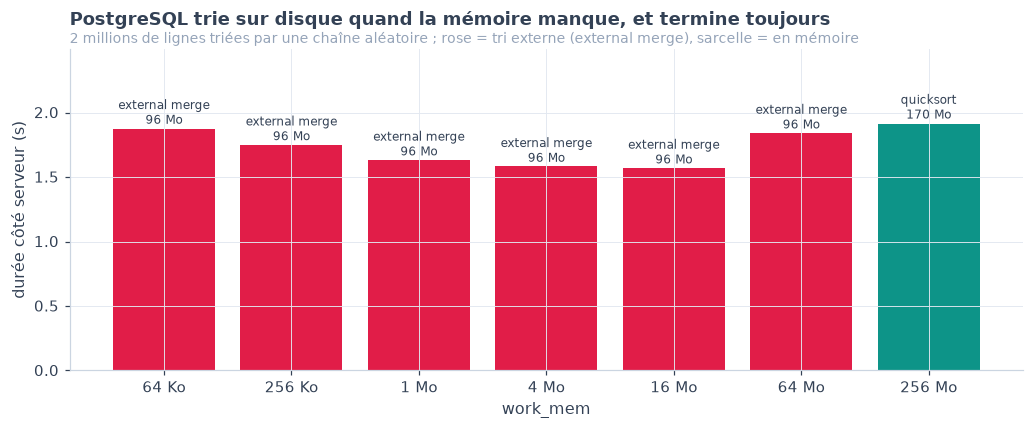

,work_mem (Ko),méthode,Ko utilisés,durée (s)
0,64,external merge,97928,1.875
1,256,external merge,97904,1.750
2,1024,external merge,97872,1.635
3,4096,external merge,97928,1.586
4,16384,external merge,97856,1.573
5,65536,external merge,97856,1.839
6,262144,quicksort,174153,1.915


In [4]:
rows = []
for wm_kb in [64, 256, 1024, 4096, 16384, 65536, 262144]:
    con.execute(f"SET work_mem = '{wm_kb}kB'")
    p = plan(requete_tri)
    m = re.search(r"Sort Method: (\w+ ?\w*)\s+(?:Memory|Disk): (\d+)kB", p)
    rows.append({"work_mem (Ko)": wm_kb, "méthode": m.group(1).strip(), "Ko utilisés": int(m.group(2)),
                 "durée (s)": duree_serveur(requete_tri, 2)})
S = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9.5, 4))
couleurs = [TEAL if "quick" in mth else ROSE for mth in S["méthode"]]
ax.bar(range(len(S)), S["durée (s)"], color=couleurs)
for i, r in S.iterrows():
    ax.text(i, r["durée (s)"] * 1.02, f"{r['méthode']}\n{r['Ko utilisés'] / 1024:.0f} Mo", ha="center", fontsize=8)
ax.set_xticks(range(len(S))); ax.set_xticklabels([f"{v // 1024} Mo" if v >= 1024 else f"{v} Ko" for v in S["work_mem (Ko)"]])
ax.set_xlabel("work_mem"); ax.set_ylabel("durée côté serveur (s)")
ax.set_ylim(0, S["durée (s)"].max() * 1.3)
ax.set_title("PostgreSQL trie sur disque quand la mémoire manque, et termine toujours")
subtitle(ax, "2 millions de lignes triées par une chaîne aléatoire ; rose = tri externe (external merge), sarcelle = en mémoire")
plt.tight_layout(); plt.show()
S

Avec 256 Mo, le tri se fait en mémoire ; en dessous, PostgreSQL passe au tri externe et
indique le volume écrit sur disque (environ 96 Mo, plus compact que les 170 Mo de
structures en mémoire). Et surprise : ici, le tri externe est **aussi rapide, voire plus
rapide**, que le tri en mémoire, même avec 64 Ko. Deux raisons. Les fichiers temporaires restent dans le
cache de pages du système : « sur disque » ne coûte presque rien. Surtout, un tri rapide
de 2 millions de lignes dispersées dans 170 Mo de mémoire multiplie les défauts de cache
du processeur, alors que le tri externe trie des segments qui tiennent dans le cache
puis les fusionne séquentiellement. Le tri externe n'est donc pas un pis-aller : c'est
un algorithme efficace, qui termine quelle que soit la mémoire, et dont le coût croît
lentement quand elle diminue (comme au cours 1).

> **À retenir.** Un moteur SQL applique le même tri externe que `sort` : segments triés
> puis fusion. `EXPLAIN ANALYZE` le révèle (*external merge*, volume disque).

## 2. Agréger par hachage ou par tri

Pour un `GROUP BY`, PostgreSQL choisit entre une **agrégation par hachage**
(*HashAggregate* : une table de hachage des groupes, comme le script Python du cours 1)
et une **agrégation par tri** (*GroupAggregate* : trier puis parcourir, comme `sort |
uniq -c`). Depuis la version 13, la table de hachage **déborde sur disque** en
partitions quand elle dépasse `work_mem`. Comptons les vues par URL (1 000 groupes) puis
par session (2 millions de groupes).

In [5]:
rows = []
for nom, sql in [("par URL (1 000 groupes)", "SELECT url, count(*) FROM events GROUP BY url"),
                 ("par session (2 M groupes)", "SELECT session, count(*) FROM events GROUP BY session")]:
    for wm in ["256MB", "4MB"]:
        con.execute(f"SET work_mem = '{wm}'")
        p = plan(sql)
        noeud = p.splitlines()[0].strip()
        detail = " ; ".join(l.strip() for l in p.splitlines() if "Batches" in l or "Sort Method" in l)
        rows.append({"requête": nom, "work_mem": wm, "plan choisi": noeud.split("(")[0],
                     "détails": detail, "durée (s)": duree_serveur(sql, 2)})
pd.DataFrame(rows)

,requête,work_mem,plan choisi,détails,durée (s)
0,par URL (1 000 groupes),256MB,HashAggregate,Batches: 1 Memory Usage: 129kB,0.158
1,par URL (1 000 groupes),4MB,HashAggregate,Batches: 1 Memory Usage: 129kB,0.156
2,par session (2 M groupes),256MB,HashAggregate,Batches: 1 Memory Usage: 286737kB,0.725
3,par session (2 M groupes),4MB,HashAggregate,Batches: 161 Memory Usage: 8465kB Disk Usage: 128120kB,0.573


Avec peu de groupes, la table de hachage est minuscule (129 Ko) : *HashAggregate*, en un
seul lot. Avec 2 millions de groupes, elle occupe 280 Mo ; limitée à 4 Mo, elle
**déborde** en 161 partitions (*Batches*) écrites sur disque puis agrégées une à une.
Le planificateur aurait pu trier (*GroupAggregate*), il a jugé le hachage partitionné
moins cher. Et comme pour le tri, la version partitionnée n'est pas plus lente ici :
chaque partition tient dans le cache du processeur, et le disque est en réalité le
cache du système. On retrouve le dilemme du cours 1 (hachage tant que l'ensemble de
travail tient en mémoire), avec une troisième voie : partitionner par hachage, puis
agréger chaque partition en mémoire.

> **À retenir.** Le planificateur choisit hachage ou tri selon le nombre de groupes
> estimé et `work_mem` ; une agrégation par hachage trop grosse se partitionne sur disque.

## 3. Les algorithmes de jointure (sections *Reduce-Side Joins and Grouping* et *Map-Side Joins*)

PostgreSQL connaît trois algorithmes, qui font écho au cours 3 :

- **Hash Join** : construit une table de hachage du plus petit côté et parcourt l'autre,
  comme la jointure par hachage diffusé ;
- **Merge Join** : trie les deux côtés sur la clé et les fusionne, comme la jointure
  tri-fusion côté reduce ;
- **Nested Loop** : pour chaque ligne d'un côté, cherche les correspondances de l'autre
  (par un index s'il existe), comme la requête par enregistrement que le livre
  déconseille dans un job de lots.

Les paramètres `enable_hashjoin`, `enable_mergejoin` et `enable_nestloop` permettent
d'interdire un algorithme pour forcer les autres. Joignons tous les événements à leur
utilisateur et agrégeons par pays.

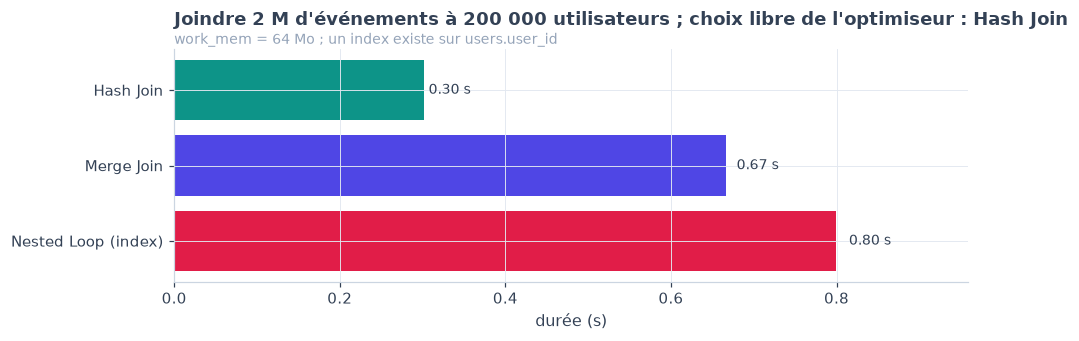

,algorithme forcé,plan obtenu,durée (s)
0,Hash Join,Hash Join,0.301
1,Merge Join,Merge Join,0.666
2,Nested Loop (index),Nested Loop,0.799


In [6]:
con.execute("SET work_mem = '64MB'")
con.execute("CREATE INDEX IF NOT EXISTS users_pk ON users (user_id)")
requete_j = """SELECT u.country, count(*), avg(e.duree_s)
               FROM events e JOIN users u ON e.user_id = u.user_id GROUP BY u.country"""
config = {"Hash Join": ("on", "off", "off"), "Merge Join": ("off", "on", "off"), "Nested Loop (index)": ("off", "off", "on")}
rows = []
for nom, (h, m_, n_) in config.items():
    con.execute(f"SET enable_hashjoin = {h}; SET enable_mergejoin = {m_}; SET enable_nestloop = {n_}")
    p = plan(requete_j)
    algo = next(l.strip().split("(")[0].replace("->", "").strip() for l in p.splitlines() if "Join" in l or "Nested Loop" in l)
    rows.append({"algorithme forcé": nom, "plan obtenu": algo, "durée (s)": duree_serveur(requete_j, 2)})
con.execute("RESET enable_hashjoin; RESET enable_mergejoin; RESET enable_nestloop")
p_libre = plan(requete_j)
choix = next(l.strip().split("(")[0].replace("->", "").strip() for l in p_libre.splitlines() if "Join" in l or "Nested Loop" in l)
J = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(J["algorithme forcé"], J["durée (s)"], color=[TEAL, INDIGO, ROSE])
for i, v in enumerate(J["durée (s)"]):
    ax.text(v * 1.02, i, f"{v:.2f} s", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, J["durée (s)"].max() * 1.2)
ax.set_xlabel("durée (s)")
ax.set_title(f"Joindre 2 M d'événements à 200 000 utilisateurs ; choix libre de l'optimiseur : {choix}")
subtitle(ax, "work_mem = 64 Mo ; un index existe sur users.user_id")
plt.tight_layout(); plt.show()
J

Laissé libre, l'optimiseur choisit la jointure par hachage : la table des utilisateurs
tient en mémoire, on la parcourt une fois, puis chaque événement y cherche sa clé. La
fusion paie le tri des 2 millions d'événements ; les boucles imbriquées paient 2 millions
de recherches dans l'index, une par ligne : c'est l'équivalent local de la « requête par
enregistrement », et le plus lent ici.

**Quand la table de hachage ne tient pas.** Si `work_mem` est trop petit pour la table
de hachage, PostgreSQL ne renonce pas : il **partitionne** les deux côtés par hachage de
la clé en plusieurs lots (*Batches*), écrits sur disque, puis joint chaque couple de
partitions séparément. C'est la jointure par hachage partitionnée (algorithme « Grace »),
le principe même de la jointure par hachage partitionné du cours 3, où chaque mappeur ne
charge qu'une partition.

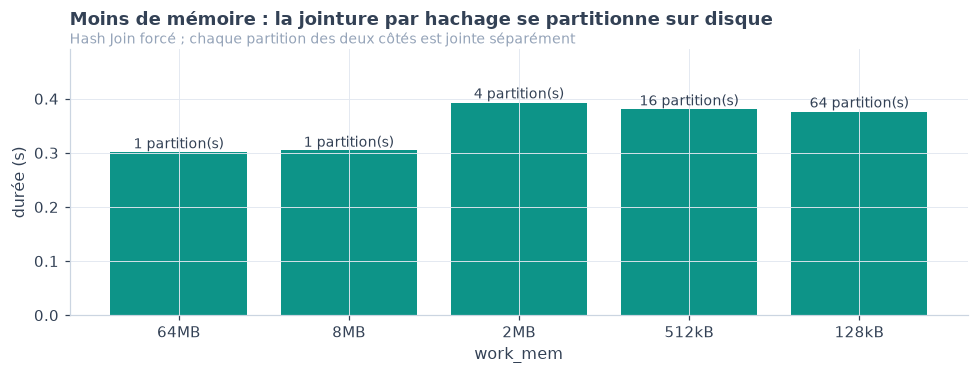

,work_mem,partitions (Batches),durée (s)
0,64MB,1,0.303
1,8MB,1,0.306
2,2MB,4,0.393
3,512kB,16,0.381
4,128kB,64,0.377


In [7]:
rows = []
con.execute("SET enable_mergejoin = off; SET enable_nestloop = off")
for wm in ["64MB", "8MB", "2MB", "512kB", "128kB"]:
    con.execute(f"SET work_mem = '{wm}'")
    p = plan(requete_j)
    m = re.search(r"Buckets: (\d+)\s+Batches: (\d+)", p)
    rows.append({"work_mem": wm, "partitions (Batches)": int(m.group(2)), "durée (s)": duree_serveur(requete_j, 2)})
con.execute("RESET enable_mergejoin; RESET enable_nestloop; SET work_mem = '64MB'")
G = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(G["work_mem"], G["durée (s)"], color=TEAL)
for i, r in G.iterrows():
    ax.text(i, r["durée (s)"] * 1.02, f"{r['partitions (Batches)']} partition(s)", ha="center", fontsize=9)
ax.set_ylim(0, G["durée (s)"].max() * 1.25)
ax.set_xlabel("work_mem"); ax.set_ylabel("durée (s)")
ax.set_title("Moins de mémoire : la jointure par hachage se partitionne sur disque")
subtitle(ax, "Hash Join forcé ; chaque partition des deux côtés est jointe séparément")
plt.tight_layout(); plt.show()
G

Le nombre de partitions croît comme l'inverse de la mémoire (×4 quand on divise
`work_mem` par 4), et la durée est multipliée par 2 à 3 dès que l'on partitionne :
il faut écrire puis relire les deux côtés de la jointure. Ensuite, elle ne bouge plus
guère : partitionner en 4 ou en 64, c'est toujours une écriture et une relecture.

> **À retenir.** Hachage si un côté tient en mémoire, fusion si les entrées sont triées
> (ou doivent l'être de toute façon), boucles imbriquées seulement pour quelques lignes.
> Une jointure par hachage trop grosse se partitionne : chaque couple de partitions est
> joint séparément, comme dans un cluster.

## 4. Le chargement en masse (section *Key-value stores as batch process output*)

Charger la sortie d'un job ligne par ligne coûte une requête (et, en autocommit, une
validation) par enregistrement. Comparons trois façons de charger 50 000 recommandations :
une transaction par ligne, toutes les lignes dans une transaction (`executemany`), et
`COPY`, le chargement en masse de PostgreSQL.

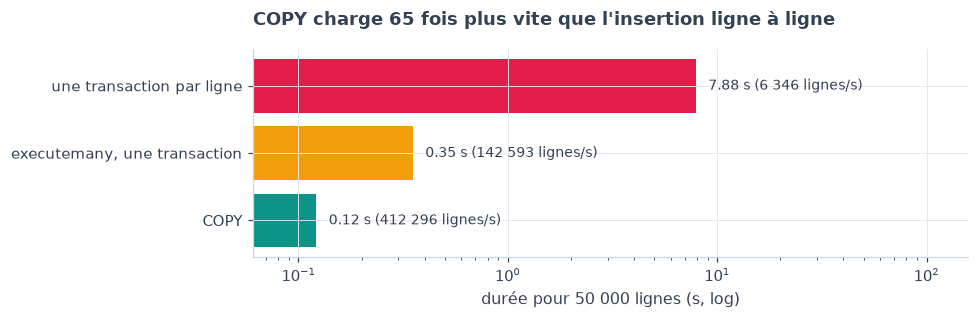

In [8]:
con.execute("DROP TABLE IF EXISTS reco")
con.execute("CREATE TABLE reco (user_id int PRIMARY KEY, items int[])")
rng = np.random.default_rng(0)
lignes = [(i, [int(x) for x in rng.integers(0, 10_000, 5)]) for i in range(50_000)]
res = {}
# 1) une transaction par ligne (sur un échantillon, extrapolé)
con.execute("TRUNCATE reco")
t0 = time.perf_counter()
for row in lignes[:3000]:
    con.execute("INSERT INTO reco VALUES (%s, %s)", row)
res["une transaction par ligne"] = (time.perf_counter() - t0) / 3000 * len(lignes)
# 2) une seule transaction, executemany
con.execute("TRUNCATE reco")
t0 = time.perf_counter()
with con.transaction():
    with con.cursor() as cur:
        cur.executemany("INSERT INTO reco VALUES (%s, %s)", lignes)
res["executemany, une transaction"] = time.perf_counter() - t0
# 3) COPY
con.execute("TRUNCATE reco")
t0 = time.perf_counter()
with con.cursor() as cur:
    with cur.copy("COPY reco (user_id, items) FROM STDIN") as cp:
        for row in lignes:
            cp.write_row(row)
res["COPY"] = time.perf_counter() - t0
assert q("SELECT count(*) FROM reco")[0][0] == len(lignes)
fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(list(res), list(res.values()), color=[ROSE, AMBER, TEAL])
for i, v in enumerate(res.values()):
    ax.text(v * 1.15, i, f"{v:.2f} s ({len(lignes) / v:,.0f} lignes/s)".replace(",", " "), va="center", fontsize=9)
ax.set_xscale("log"); ax.set_xlim(min(res.values()) / 2, max(res.values()) * 20); ax.invert_yaxis()
ax.set_xlabel("durée pour 50 000 lignes (s, log)")
ax.set_title(f"COPY charge {res['une transaction par ligne'] / res['COPY']:.0f} fois plus vite que l'insertion ligne à ligne")
plt.tight_layout(); plt.show()

Chaque transaction validée attend l'écriture de son journal (WAL) sur disque et un
aller-retour réseau ; regrouper les lignes dans une transaction supprime les
validations, `COPY` supprime en plus l'analyse d'une requête par ligne. C'est pourquoi
les systèmes qui servent des données dérivées offrent des outils de chargement en
masse, et pourquoi le livre déconseille d'écrire depuis un job ligne par ligne.

> **À retenir.** Le chargement en masse (`COPY`, fichiers préconstruits) est d'un à deux
> ordres de grandeur plus rapide que l'insertion ligne à ligne.